In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import seaborn as sns
import os

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.utils import load_img, img_to_array
from PIL import Image

from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

In [2]:
# Reproducibility
SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

In [3]:
# Konfigurasi
sns.set_style('whitegrid')
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
CLASS_NAMES = ['Monkeypox', 'Others']

In [4]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("nafin59/monkeypox-skin-lesion-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'monkeypox-skin-lesion-dataset' dataset.
Path to dataset files: /kaggle/input/monkeypox-skin-lesion-dataset


In [5]:
os.listdir(os.path.join(path, 'Fold1', 'Fold1', 'Fold1'))

['Val', 'Test', 'Train']

In [6]:
train_dir = os.path.join(path, 'Fold1', 'Fold1', 'Fold1', 'Train')
test_dir = os.path.join(path, 'Fold1', 'Fold1', 'Fold1', 'Test')
val_dir = os.path.join(path, 'Fold1', 'Fold1', 'Fold1', 'Val')

In [7]:
for name, d in [('Train', train_dir), ('Val', val_dir), ('Test', test_dir)]:
    for cls in sorted(os.listdir(d)):
        n = len(os.listdir(os.path.join(d, cls)))
        print(f'{name} {cls} = {n} gambar')

Train Monkeypox = 980 gambar
Train Others = 1162 gambar
Val Monkeypox = 168 gambar
Val Others = 252 gambar
Test Monkeypox = 20 gambar
Test Others = 25 gambar


In [8]:
train_monkeypox_img_path = os.path.join(train_dir, 'Monkeypox', os.listdir(os.path.join(train_dir, 'Monkeypox'))[13])
train_others_img_path = os.path.join(train_dir, 'Others', os.listdir(os.path.join(train_dir, 'Others'))[13])

In [9]:
monkeypox_arr = mpimg.imread(train_monkeypox_img_path)
monkeypox_arr

array([[[  8,   0,   0],
        [ 13,   0,   0],
        [ 22,   0,   0],
        ...,
        [238, 234, 225],
        [240, 233, 223],
        [240, 233, 223]],

       [[  8,   0,   0],
        [ 13,   0,   0],
        [ 23,   0,   0],
        ...,
        [238, 234, 225],
        [238, 234, 223],
        [238, 234, 223]],

       [[  9,   0,   0],
        [ 13,   0,   0],
        [ 24,   0,   0],
        ...,
        [237, 234, 225],
        [237, 234, 225],
        [237, 234, 225]],

       ...,

       [[  0,   2,   0],
        [  0,   2,   0],
        [  0,   0,   0],
        ...,
        [  0,   0,   2],
        [  0,   0,   2],
        [  0,   0,   2]],

       [[  0,   1,   0],
        [  0,   1,   0],
        [  3,   0,   0],
        ...,
        [  1,   0,   0],
        [  1,   0,   0],
        [  1,   0,   0]],

       [[  1,   1,   0],
        [  3,   0,   0],
        [  4,   0,   0],
        ...,
        [  3,   0,   0],
        [  3,   0,   0],
        [  3,   0,   0]]

In [10]:
monkeypox_arr.shape

(224, 224, 3)

Menghitung jumlah gambar pada setiap kelas pada data uji

In [11]:
train_mkpox_total_images = len(os.listdir(os.path.join(train_dir, 'Monkeypox')))
train_other_total_images = len(os.listdir(os.path.join(train_dir, 'Others')))
df_train_counts = pd.DataFrame({
    'Class': ['Monkeypox', 'Others'],
    'Counts': [train_mkpox_total_images, train_other_total_images]
})

df_train_counts

,Class,Counts
0,Monkeypox,980
1,Others,1162


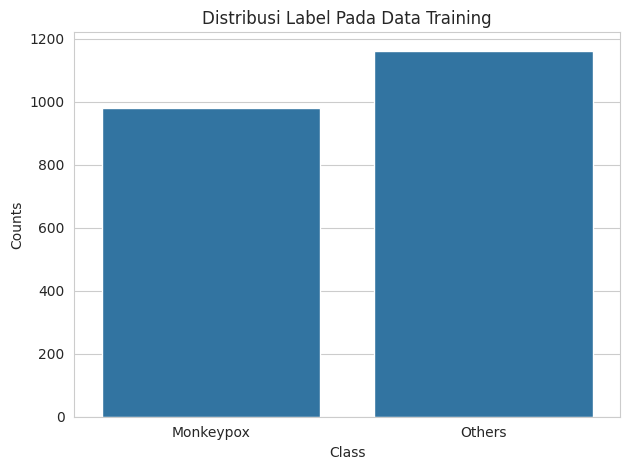

In [12]:
sns.barplot(x='Class', y='Counts', data=df_train_counts)
plt.title('Distribusi Label Pada Data Training')
plt.tight_layout()

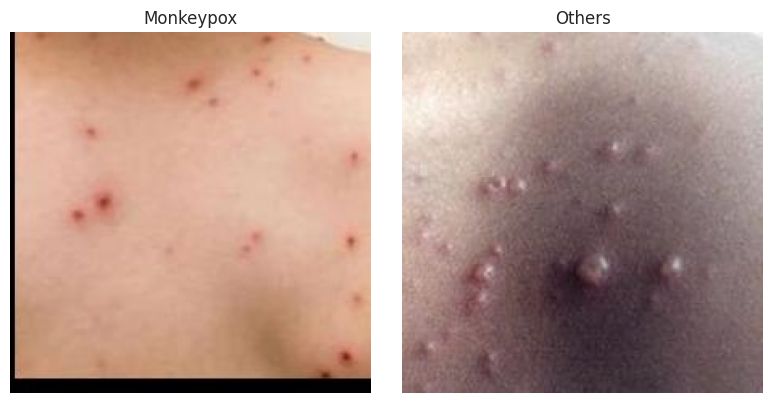

In [13]:
pox_img = Image.open(train_monkeypox_img_path)
others_img = Image.open(train_others_img_path)
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(pox_img)
ax[0].set_title('Monkeypox')
ax[0].axis('off')
ax[1].imshow(others_img)
ax[1].set_title('Others')
ax[1].axis('off')
fig.tight_layout()
plt.show()


# Preprocessing

In [14]:
# Train
# train_datagen = ImageDataGenerator(
#     rescale=1./255,
#     # Opsional
#     rotation_range=10,
#     zoom_range=0.1,
#     horizontal_flip=True,
#     fill_mode='nearest'
# )

datagen = ImageDataGenerator(rescale=1./255)

train_generator = datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    classes=CLASS_NAMES,
    shuffle=True,
    seed=SEED
)

val_generator = datagen.flow_from_directory(
    val_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    classes=CLASS_NAMES,
    shuffle=False
)

test_generator = datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    classes=CLASS_NAMES,
    shuffle=False
)

print("\nClass indices:", train_generator.class_indices)

Found 2142 images belonging to 2 classes.
Found 420 images belonging to 2 classes.
Found 45 images belonging to 2 classes.

Class indices: {'Monkeypox': 0, 'Others': 1}


In [15]:
# Opsional Buat Data Imbalance
# class_weights_arr = compute_class_weight(
#     class_weight='balanced',
#     classes=np.unique(train_generator.classes),
#     y=train_generator.classes
# )
# class_weights = dict(enumerate(class_weights_arr))
# print("Class weights:", class_weights)

In [16]:
x_batch, y_batch = next(train_generator)
print("Shape batch gambar :", x_batch.shape)
print("Shape batch label  :", y_batch.shape)
print("Range piksel       :", x_batch.min(), "-", x_batch.max())
print("Jumlah batch/epoch :", len(train_generator))

Shape batch gambar : (32, 224, 224, 3)
Shape batch label  : (32,)
Range piksel       : 0.0 - 1.0
Jumlah batch/epoch : 67
